# Sequential Confidence-Cascade Ensemble

## ISIC 2019 Binary Classification



**Strategy:** Models act as a chain of command.

- If Model 1 is highly confident → trust it, skip others.

- If Model 1 is confused → pass to Model 2, and so on.

- Final fallback → AUC-weighted average of all confused models.



**No retraining needed. Uses existing .npy files.**

In [1]:
import os

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from itertools import product

from collections import Counter

from sklearn.metrics import (

    accuracy_score, roc_auc_score, roc_curve,

    classification_report, confusion_matrix

)

print("Libraries loaded.")

Libraries loaded.


In [2]:
# ── Cell 2: Paths & Registry ─────────────────────────────────────────────────
NPY_DIR = '/kaggle/input/notebooks/nandini143/'

# Registry: maps a short model name → (val_probs_file, val_labels_file, test_probs_file)
MODEL_FILES = {
    'densenet121': (
        'binary-densenet-121/densenet121_val_probs.npy',
        'binary-densenet-121/densenet121_val_labels.npy',
        'binary-densenet-121/densenet121_test_probs.npy',
        'binary-densenet-121/densenet121_test_labels.npy',
    ),
    'convnext': (
        'binary-convnext/convnext_val_probs.npy',
        'binary-convnext/convnext_val_labels.npy',
        'binary-convnext/convnext_test_probs.npy',
        'binary-convnext/convnext_test_labels.npy',
    ),
    'efficientnetv2s': (
        'binary-efficientnetv2s/efficientnetv2s_val_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_val_labels.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_labels.npy',
    ),
    'swintiny': (
        'binary-swin-tiny-transformer/swintiny_val_probs.npy',
        'binary-swin-tiny-transformer/swintiny_val_labels.npy',
        'binary-swin-tiny-transformer/swintiny_test_probs.npy',
        'binary-swin-tiny-transformer/swintiny_test_labels.npy',
    ),
}
print('NPY_DIR:', NPY_DIR)
CASCADE_ORDER = ['efficientnetv2s', 'swintiny', 'convnext', 'densenet121']

print('Cascade order:', CASCADE_ORDER)

NPY_DIR: /kaggle/input/notebooks/nandini143/
Cascade order: ['efficientnetv2s', 'swintiny', 'convnext', 'densenet121']


In [3]:
# ── Cell 3: Load All .npy Files ──────────────────────────────────────────────

val_probs_dict   = {}

val_labels_dict  = {}

test_probs_dict  = {}

test_labels_dict = {}

val_aucs         = {}

skipped          = []



print('Loading predictions...')

print('-' * 65)



for model_name, (vp_f, vl_f, tp_f, tl_f) in MODEL_FILES.items():

    vp = os.path.join(NPY_DIR, vp_f)

    vl = os.path.join(NPY_DIR, vl_f)

    tp = os.path.join(NPY_DIR, tp_f)

    tl = os.path.join(NPY_DIR, tl_f)

    missing = [f for f in [vp, vl, tp, tl] if not os.path.exists(f)]

    if missing:

        print(f'  [SKIP-MISSING]  {model_name:20s} -- {[os.path.basename(m) for m in missing]}')

        skipped.append(model_name)

        continue

    val_probs   = np.load(vp)

    val_labels  = np.load(vl).astype(int)

    test_probs  = np.load(tp)

    test_labels = np.load(tl).astype(int)

    if len(val_probs) != len(val_labels):

        print(f'  [SKIP-MISMATCH] {model_name:20s} -- val_probs/val_labels size mismatch')

        skipped.append(model_name)

        continue

    val_probs_dict[model_name]   = val_probs

    val_labels_dict[model_name]  = val_labels

    test_probs_dict[model_name]  = test_probs

    test_labels_dict[model_name] = test_labels

    auc     = roc_auc_score(val_labels, val_probs)

    val_acc = accuracy_score(val_labels, (val_probs >= 0.5).astype(int))

    val_aucs[model_name] = auc

    print(f'  [OK]  {model_name:20s}  val_AUC={auc:.4f}  val_ACC={val_acc*100:.2f}%  n_val={len(val_probs)}  n_test={len(test_probs)}')



CASCADE_ORDER = [m for m in CASCADE_ORDER if m in val_probs_dict]

if skipped:

    print(f'WARNING: Skipped {skipped}')

if len(CASCADE_ORDER) == 0:

    raise RuntimeError('No valid models loaded.')

print(f'Effective cascade order: {CASCADE_ORDER}')

true_test_labels = test_labels_dict[CASCADE_ORDER[0]]

print(f'True test labels loaded: n={len(true_test_labels)}')

Loading predictions...
-----------------------------------------------------------------
  [OK]  densenet121           val_AUC=0.9479  val_ACC=87.29%  n_val=2533  n_test=2534
  [OK]  convnext              val_AUC=0.9623  val_ACC=90.84%  n_val=2533  n_test=2534
  [OK]  efficientnetv2s       val_AUC=0.9698  val_ACC=92.30%  n_val=2533  n_test=2534
  [OK]  swintiny              val_AUC=0.9596  val_ACC=89.22%  n_val=2533  n_test=2534
Effective cascade order: ['efficientnetv2s', 'swintiny', 'convnext', 'densenet121']
True test labels loaded: n=2534


In [4]:
# ── Cell 4: Individual Model Accuracy Baseline ───────────────────────────────

print('=' * 70)

print('  INDIVIDUAL MODEL BASELINE (Val-Optimized Threshold)')

print('=' * 70)

print(f'  {"Model":<22}  {"Val ACC":>10}  {"Opt Thresh":>12}  {"Test ACC":>12}')

print('  ' + '-' * 62)

model_thresholds = {}

for m in CASCADE_ORDER:

    best_thresh, best_val_acc = 0.5, 0

    for t in np.linspace(0.1, 0.9, 81):

        acc = accuracy_score(val_labels_dict[m], (val_probs_dict[m] >= t).astype(int))

        if acc > best_val_acc:

            best_val_acc, best_thresh = acc, t

    model_thresholds[m] = best_thresh

    test_acc = accuracy_score(true_test_labels, (test_probs_dict[m] >= best_thresh).astype(int))

    print(f'  {m:<22}  {best_val_acc:>10.4f}  {best_thresh:>12.2f}  {test_acc*100:>11.2f}%')

print('=' * 70)

  INDIVIDUAL MODEL BASELINE (Val-Optimized Threshold)
  Model                      Val ACC    Opt Thresh      Test ACC
  --------------------------------------------------------------
  efficientnetv2s             0.9230          0.41        90.96%
  swintiny                    0.9088          0.36        90.06%
  convnext                    0.9092          0.48        90.21%
  densenet121                 0.8843          0.43        88.24%


In [5]:
# ── Cell 5: Core Cascade Logic ───────────────────────────────────────────────

# For each sample:

#   1. If Model 1 prob >= high_conf OR <= low_conf → it is confident → trust it

#   2. Otherwise → pass to next model in chain

#   3. If all models are unsure → AUC-weighted average of all predictions



def run_cascade(probs_dict, order, high_conf, low_conf, aucs):

    n = len(probs_dict[order[0]])

    final_probs = np.full(n, -1.0)

    model_used  = ['fallback'] * n

    undecided   = np.ones(n, dtype=bool)

    for model in order:

        if not np.any(undecided):

            break

        probs = probs_dict[model]

        confident_mask = undecided & ((probs >= high_conf) | (probs <= low_conf))

        final_probs[confident_mask] = probs[confident_mask]

        for idx in np.where(confident_mask)[0]:

            model_used[idx] = model

        undecided[confident_mask] = False

    if np.any(undecided):

        total_auc = sum(aucs[m] for m in order)

        fallback = sum(aucs[m] / total_auc * probs_dict[m] for m in order)

        final_probs[undecided] = fallback[undecided]

    return final_probs, model_used



print('Cascade logic defined.')

Cascade logic defined.


In [6]:
# ── Cell 6: Grid Search — Find Optimal (high_conf, low_conf) ────────────────

ref_labels = val_labels_dict[CASCADE_ORDER[0]]

HIGH_CONFS = np.arange(0.55, 0.96, 0.05)

LOW_CONFS  = np.arange(0.04, 0.46, 0.05)



print('Grid searching optimal cascade thresholds on Validation Set...')

print('Optimizing for ACCURACY')



best_val_acc, best_high, best_low = 0, 0.7, 0.3

results = []

for high, low in product(HIGH_CONFS, LOW_CONFS):

    if high <= low:

        continue

    fp, _ = run_cascade(val_probs_dict, CASCADE_ORDER, high, low, val_aucs)

    acc = accuracy_score(ref_labels, (fp >= 0.5).astype(int))

    results.append((acc, high, low))

    if acc > best_val_acc:

        best_val_acc, best_high, best_low = acc, high, low



print(f'Best Validation Accuracy  : {best_val_acc*100:.2f}%')

print(f'Optimal High Confidence   : >= {best_high:.2f}  (trust Malignant)')

print(f'Optimal Low  Confidence   : <= {best_low:.2f}   (trust Benign)')

Grid searching optimal cascade thresholds on Validation Set...
Optimizing for ACCURACY
Best Validation Accuracy  : 92.85%
Optimal High Confidence   : >= 0.55  (trust Malignant)
Optimal Low  Confidence   : <= 0.24   (trust Benign)


In [7]:
# -- Cell META: Metadata-Aware Cascade Confidence Adjustment --
# The cascade (Cell 5-7) routes samples based on confidence thresholds.
# Here we add a Logistic Regression that takes:
#   (a) the cascade output probability, AND
#   (b) clinical metadata
# to produce a final adjusted prediction. This lets the model raise/lower
# confidence for specific demographic subgroups without re-engineering the
# cascade logic.

import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

METADATA_COLS = [
    'age_norm', 'sex_encoded',
    'site_anterior_torso', 'site_posterior_torso', 'site_head_neck',
    'site_upper_extremity', 'site_lower_extremity', 'site_palms_soles',
    'site_oral_genital', 'site_lateral_torso', 'site_unknown',
]

_csv_dir  = '/kaggle/input/notebooks/nandini143/data-preparation'
_val_csv  = os.path.join(_csv_dir, 'binary_val.csv')
_test_csv = os.path.join(_csv_dir, 'binary_test.csv')

meta_cascade_val  = None
meta_cascade_test = None

if os.path.exists(_val_csv) and os.path.exists(_test_csv):
    _vdf = pd.read_csv(_val_csv)
    _tdf = pd.read_csv(_test_csv)
    _vcols = [c for c in METADATA_COLS if c in _vdf.columns]

    if _vcols:
        _mval  = _vdf[_vcols].fillna(0).values.astype('float32')
        _mtest = _tdf[_vcols].fillna(0).values.astype('float32')

        # Stack all base-model probs + metadata
        _vp = np.column_stack([val_probs_dict[m]  for m in CASCADE_ORDER])
        _tp = np.column_stack([test_probs_dict[m] for m in CASCADE_ORDER])

        if len(_mval) == len(_vp) and len(_mtest) == len(_tp):
            X_vm = np.hstack([_vp, _mval])
            X_tm = np.hstack([_tp, _mtest])

            meta_casc_lr = LogisticRegression(C=0.1, max_iter=1000, solver='lbfgs', random_state=42)
            meta_casc_lr.fit(X_vm, ref_labels)

            meta_cascade_val  = meta_casc_lr.predict_proba(X_vm)[:, 1]
            meta_cascade_test = meta_casc_lr.predict_proba(X_tm)[:, 1]

            _auc = roc_auc_score(ref_labels, meta_cascade_val)
            _acc = accuracy_score(ref_labels, (meta_cascade_val >= 0.5).astype(int))

            print('=' * 65)
            print('  [META] Cascade Probs + Metadata LR Adjuster')
            print(f'  Features : {len(CASCADE_ORDER)} cascade model probs + {len(_vcols)} metadata cols')
            print(f'  Val AUC  : {_auc:.4f}')
            print(f'  Val ACC  : {_acc*100:.2f}%')
            print('=' * 65)
            print('  Cascade model coefficients:')
            for nm, c in zip(CASCADE_ORDER, meta_casc_lr.coef_[0][:len(CASCADE_ORDER)]):
                print(f'    {nm:22s}  coef = {c:+.4f}')
            print('  Metadata coefficients:')
            for nm, c in zip(_vcols, meta_casc_lr.coef_[0][len(CASCADE_ORDER):]):
                print(f'    {nm:25s}  coef = {c:+.4f}')
        else:
            print('[META] WARNING: row count mismatch.')
    else:
        print('[META] No metadata columns found in CSV.')
else:
    print(f'[META] CSVs not found at {_csv_dir}. Skipping cascade metadata adjuster.')

  [META] Cascade Probs + Metadata LR Adjuster
  Features : 4 cascade model probs + 11 metadata cols
  Val AUC  : 0.9753
  Val ACC  : 92.50%
  Cascade model coefficients:
    efficientnetv2s         coef = +2.9675
    swintiny                coef = +1.7209
    convnext                coef = +2.0585
    densenet121             coef = +1.1820
  Metadata coefficients:
    age_norm                   coef = +0.9225
    sex_encoded                coef = -0.1096
    site_anterior_torso        coef = -0.0092
    site_posterior_torso       coef = +0.0258
    site_head_neck             coef = +0.0704
    site_upper_extremity       coef = -0.0120
    site_lower_extremity       coef = -0.1312
    site_palms_soles           coef = +0.1535
    site_oral_genital          coef = -0.1096
    site_lateral_torso         coef = +0.0862
    site_unknown               coef = -0.0827


In [8]:
# ── Cell 7: Apply Optimal Cascade to Test Set ────────────────────────────────

val_final, val_model_used = run_cascade(val_probs_dict,  CASCADE_ORDER, best_high, best_low, val_aucs)

test_final, _             = run_cascade(test_probs_dict, CASCADE_ORDER, best_high, best_low, val_aucs)



val_preds  = (val_final  >= 0.5).astype(int)

test_preds = (test_final >= 0.5).astype(int)



val_acc_cascade  = accuracy_score(ref_labels,        val_preds)

test_acc_cascade = accuracy_score(true_test_labels,  test_preds)

test_auc_cascade = roc_auc_score(true_test_labels,   test_final)



print()

print('=' * 62)

print('   SEQUENTIAL CASCADE ENSEMBLE — FINAL RESULTS')

print('=' * 62)

print(f'   Cascade Order             : {CASCADE_ORDER}')

print(f'   High Confidence Threshold : >= {best_high:.2f}')

print(f'   Low  Confidence Threshold : <= {best_low:.2f}')

print(f'   Val  Accuracy (optimized) : {val_acc_cascade*100:.2f}%')

print(f'   Test Accuracy             : {test_acc_cascade*100:.2f}%')

print(f'   Test AUC                  : {test_auc_cascade:.4f}')

print('=' * 62)



handled = Counter(val_model_used)

total   = len(val_model_used)

print('Val Set — samples handled per stage:')

for m in CASCADE_ORDER + ['fallback']:

    n = handled.get(m, 0)

    print(f'  {m:22s}  {n:5d} samples  ({n/total*100:.1f}%)')


   SEQUENTIAL CASCADE ENSEMBLE — FINAL RESULTS
   Cascade Order             : ['efficientnetv2s', 'swintiny', 'convnext', 'densenet121']
   High Confidence Threshold : >= 0.55
   Low  Confidence Threshold : <= 0.24
   Val  Accuracy (optimized) : 92.85%
   Test Accuracy             : 91.67%
   Test AUC                  : 0.9649
Val Set — samples handled per stage:
  efficientnetv2s          2220 samples  (87.6%)
  swintiny                  173 samples  (6.8%)
  convnext                   62 samples  (2.4%)
  densenet121                10 samples  (0.4%)
  fallback                   68 samples  (2.7%)


Classification Report (Test Set):
               precision    recall  f1-score   support

   Benign (0)     0.9306    0.9381    0.9343      1600
Malignant (1)     0.8925    0.8801    0.8863       934

     accuracy                         0.9167      2534
    macro avg     0.9115    0.9091    0.9103      2534
 weighted avg     0.9165    0.9167    0.9166      2534



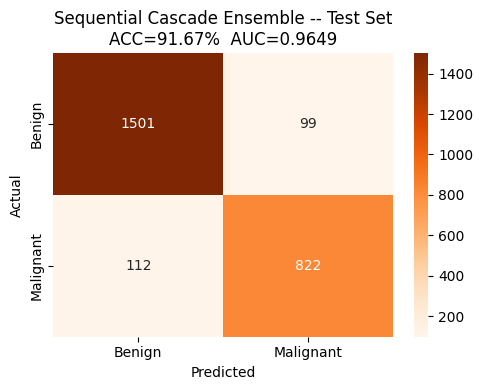

cascade_test_confusion.png saved


In [9]:
# ── Cell 8: Classification Report & Confusion Matrix ─────────────────────────

print('Classification Report (Test Set):')

print(classification_report(true_test_labels, test_preds,

      target_names=['Benign (0)', 'Malignant (1)'], digits=4))



fig, ax = plt.subplots(figsize=(5, 4))

cm = confusion_matrix(true_test_labels, test_preds)

sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=ax,

            xticklabels=['Benign', 'Malignant'],

            yticklabels=['Benign', 'Malignant'])

ax.set_title(f'Sequential Cascade Ensemble -- Test Set\nACC={test_acc_cascade*100:.2f}%  AUC={test_auc_cascade:.4f}')

ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig('/kaggle/working/cascade_test_confusion.png', dpi=150, bbox_inches='tight')

plt.show()

print('cascade_test_confusion.png saved')

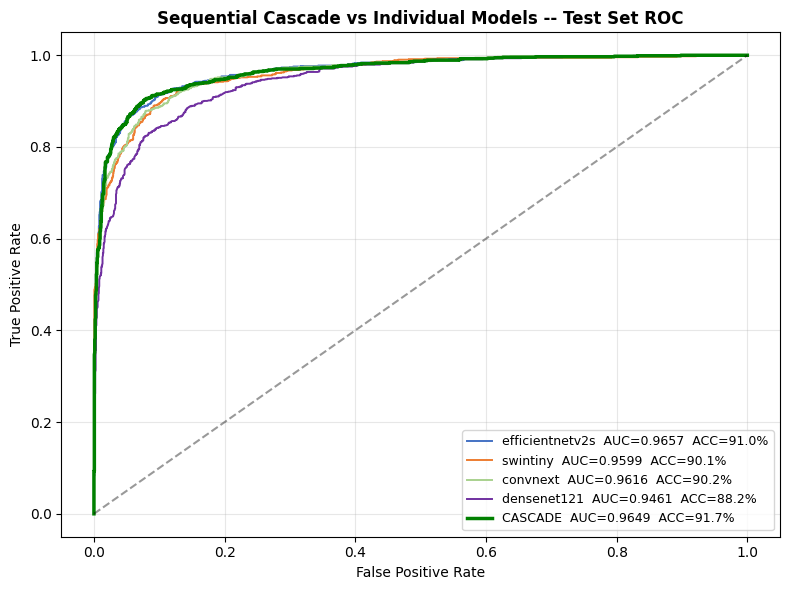

cascade_roc_curves.png saved


In [10]:
# ── Cell 9: ROC Curve — Cascade vs Individual Models ─────────────────────────

fig, ax = plt.subplots(figsize=(8, 6))

colors = ['#4472C4', '#ED7D31', '#A9D18E', '#7030A0']

for model, color in zip(CASCADE_ORDER, colors):

    fpr, tpr, _ = roc_curve(true_test_labels, test_probs_dict[model])

    auc = roc_auc_score(true_test_labels, test_probs_dict[model])

    acc = accuracy_score(true_test_labels, (test_probs_dict[model] >= model_thresholds[model]).astype(int))

    ax.plot(fpr, tpr, color=color, lw=1.4,

            label=f'{model}  AUC={auc:.4f}  ACC={acc*100:.1f}%')



fpr_c, tpr_c, _ = roc_curve(true_test_labels, test_final)

ax.plot(fpr_c, tpr_c, 'g-', lw=2.5,

        label=f'CASCADE  AUC={test_auc_cascade:.4f}  ACC={test_acc_cascade*100:.1f}%')

ax.plot([0,1],[0,1], 'k--', alpha=0.4)

ax.set_title('Sequential Cascade vs Individual Models -- Test Set ROC', fontweight='bold')

ax.set_xlabel('False Positive Rate')

ax.set_ylabel('True Positive Rate')

ax.legend(loc='lower right', fontsize=9)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/cascade_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print('cascade_roc_curves.png saved')

In [11]:
# ── Cell 10: Top 10 Threshold Combinations — Val vs Test Accuracy Tradeoff ───

print('=' * 75)

print('  TOP 10 THRESHOLD COMBINATIONS (by Val Accuracy)')

print('=' * 75)

print(f'  {"High Conf":>12}  {"Low Conf":>10}  {"Val ACC":>10}  {"Test ACC":>12}')

print('  ' + '-' * 55)



results.sort(reverse=True, key=lambda x: x[0])

for val_acc, h, l in results[:10]:

    tp, _ = run_cascade(test_probs_dict, CASCADE_ORDER, h, l, val_aucs)

    t_acc = accuracy_score(true_test_labels, (tp >= 0.5).astype(int))

    tag = '  <-- BEST' if (abs(h - best_high) < 0.001 and abs(l - best_low) < 0.001) else ''

    print(f'  {h:>12.2f}  {l:>10.2f}  {val_acc*100:>10.2f}%  {t_acc*100:>11.2f}%{tag}')

print('=' * 75)

  TOP 10 THRESHOLD COMBINATIONS (by Val Accuracy)
     High Conf    Low Conf     Val ACC      Test ACC
  -------------------------------------------------------
          0.55        0.24       92.85%        91.67%  <-- BEST
          0.55        0.29       92.81%        91.79%
          0.55        0.39       92.70%        91.44%
          0.65        0.24       92.70%        91.87%
          0.55        0.19       92.66%        91.59%
          0.55        0.34       92.66%        91.75%
          0.65        0.19       92.62%        91.83%
          0.65        0.29       92.62%        91.83%
          0.60        0.24       92.58%        91.83%
          0.55        0.44       92.54%        91.52%


In [12]:
# ── Cell 11: Save Test Predictions & Submission CSV ──────────────────────────
np.save('/kaggle/working/cascade_test_probs.npy', test_final)
print('cascade_test_probs.npy saved')



TEST_CSV_PATH = os.path.join('/kaggle/input/notebooks/nandini143/data-preparation', 'binary_test.csv')

if os.path.exists(TEST_CSV_PATH):

    test_df = pd.read_csv(TEST_CSV_PATH)

    if len(test_df) != len(test_final):

        print(f'WARNING: CSV rows={len(test_df)} but predictions={len(test_final)}')

    else:

        submission = pd.DataFrame({'image': test_df['image'], 'target': test_final})

        sub_path = os.path.join('/kaggle/working', 'cascade_submission.csv')
        submission.to_csv(sub_path, index=False)

        print(f'cascade_submission.csv saved -> {sub_path}')

        print(submission.head())

else:

    print(f'binary_test.csv not found. Probabilities in cascade_test_probs.npy')

cascade_test_probs.npy saved
cascade_submission.csv saved -> /kaggle/working/cascade_submission.csv
          image    target
0  ISIC_0068116  0.855469
1  ISIC_0067282  0.018005
2  ISIC_0054002  0.027039
3  ISIC_0000514  0.107422
4  ISIC_0070840  0.117859


In [13]:
# ── Cell 12: Final Summary ───────────────────────────────────────────────────

print('=' * 65)

print('  SEQUENTIAL CASCADE ENSEMBLE -- COMPLETE SUMMARY')

print('=' * 65)

print(f'  Cascade Order      : {" -> ".join(CASCADE_ORDER)}')

print(f'  High Conf Thresh   : >= {best_high:.2f}  (trusted Malignant)')

print(f'  Low  Conf Thresh   : <= {best_low:.2f}   (trusted Benign)')

print()

print(f'  Val  Accuracy      : {val_acc_cascade*100:.2f}%')

print(f'  Test Accuracy      : {test_acc_cascade*100:.2f}%')

print(f'  Test AUC           : {test_auc_cascade:.4f}')

print()

print('  Outputs:')

print('    cascade_test_probs.npy')

print('    cascade_test_confusion.png')

print('    cascade_roc_curves.png')

print('    cascade_submission.csv')

print('=' * 65)

  SEQUENTIAL CASCADE ENSEMBLE -- COMPLETE SUMMARY
  Cascade Order      : efficientnetv2s -> swintiny -> convnext -> densenet121
  High Conf Thresh   : >= 0.55  (trusted Malignant)
  Low  Conf Thresh   : <= 0.24   (trusted Benign)

  Val  Accuracy      : 92.85%
  Test Accuracy      : 91.67%
  Test AUC           : 0.9649

  Outputs:
    cascade_test_probs.npy
    cascade_test_confusion.png
    cascade_roc_curves.png
    cascade_submission.csv
